# RuPropManagementEval — Analysis Playground

Exploratory analysis of `results/grades.tsv`.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('../results/grades.tsv', sep='\t')
df.head()

,model,judge,question_id,category,question,n_runs,total_awarded_avg,total_awarded_min,total_awarded_max,total_max_avg,...,completion_tokens_max,total_tokens_avg,total_tokens_min,total_tokens_max,cost_avg,cost_min,cost_max,elapsed_s_avg,elapsed_s_min,elapsed_s_max
0,GigaChat-2-Max,qwen3.6-35b-a3b,9656,oss,"Добрый день, коллеги. Ситуация такая. Активный...",1,1.5,1.5,1.5,6.0,...,246,542.0,542,542,0.35230,0.35230,0.35230,31.87,31.87,31.87
1,GigaChat-2-Max,qwen3.6-35b-a3b,1761,uk_management,"Добрый вечер коллеги,скажите пожалуйста как вы...",1,0.5,0.5,0.5,6.0,...,485,645.0,645,645,0.41925,0.41925,0.41925,34.80,34.80,34.80
2,GigaChat-2-Max,qwen3.6-35b-a3b,2280,it,Ребят что на сайте ук должно быть обязательно?,1,0.0,0.0,0.0,7.0,...,198,224.0,224,224,0.14560,0.14560,0.14560,37.60,37.60,37.60
3,GigaChat-2-Max,qwen3.6-35b-a3b,8948,oss,"Добрый день! Коллеги, такой вопрос. Здание с а...",1,0.0,0.0,0.0,7.0,...,325,538.0,538,538,0.34970,0.34970,0.34970,38.68,38.68,38.68
4,GigaChat-2-Max,qwen3.6-35b-a3b,2533,payment,"Всем привет. Вопрос такой, смущает меня. У нас...",1,2.0,2.0,2.0,3.0,...,454,650.0,650,650,0.42250,0.42250,0.42250,25.01,25.01,25.01


## Leaderboard (sorted by score_avg)

In [ ]:
leaderboard = df.groupby('model').agg(
    total_awarded=('total_awarded_avg', 'sum'),
    total_max=('total_max_avg', 'sum'),
    n_questions=('question_id', 'count'),
    tokens=('total_tokens_avg', 'sum'),
    cost=('cost_avg', 'sum'),
    halluc=('factual_correctness_avg', lambda s: int((1 - s).sum())),
).reset_index()
leaderboard['pct'] = leaderboard['total_awarded'] / leaderboard['total_max'] * 100
leaderboard = leaderboard.sort_values('pct', ascending=True)
leaderboard

## Score Distribution

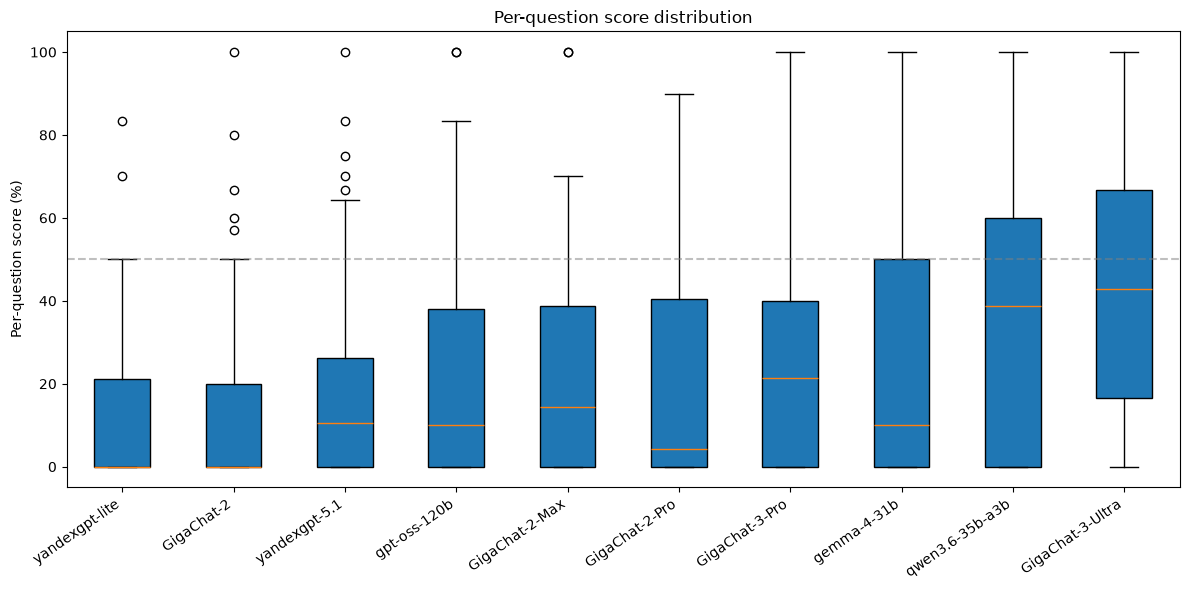

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))
data = []
labels = []
for model in leaderboard['model']:
    scores = df[df['model'] == model]['score_avg'].dropna() * 100
    data.append(scores.values)
    labels.append(model)
bp = ax.boxplot(data, tick_labels=labels, patch_artist=True, widths=0.5)
ax.set_xticklabels(labels, rotation=35, ha='right')
ax.set_ylabel('Per-question score (%)')
ax.set_title('Per-question score distribution')
ax.axhline(y=50, color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Per-Category Breakdown

In [6]:
pivot = df.pivot_table(
    index='category',
    columns='model',
    values='score_avg',
    aggfunc='mean',
) * 100
pivot = pivot[leaderboard['model'].values]  # sort columns by overall pct
pivot.round(0)

model,yandexgpt-lite,GigaChat-2,yandexgpt-5.1,gpt-oss-120b,GigaChat-2-Max,GigaChat-2-Pro,GigaChat-3-Pro,gemma-4-31b,qwen3.6-35b-a3b,GigaChat-3-Ultra
category,,,,,,,,,,
conflicts,3.0,16.0,28.0,12.0,9.0,28.0,47.0,50.0,28.0,49.0
it,20.0,10.0,10.0,25.0,0.0,15.0,20.0,0.0,0.0,25.0
ku,0.0,0.0,6.0,0.0,6.0,6.0,0.0,12.0,19.0,25.0
law,9.0,18.0,17.0,12.0,9.0,21.0,22.0,9.0,32.0,36.0
oss,9.0,15.0,24.0,28.0,27.0,20.0,17.0,24.0,61.0,40.0
payment,19.0,24.0,24.0,31.0,30.0,35.0,39.0,35.0,43.0,49.0
repair,20.0,18.0,18.0,30.0,42.0,22.0,30.0,17.0,48.0,43.0
uk_management,12.0,10.0,16.0,20.0,22.0,17.0,20.0,31.0,31.0,48.0
water,8.0,8.0,17.0,8.0,0.0,8.0,67.0,0.0,58.0,17.0


## Hardest Questions (lowest avg across all models)

In [7]:
hardest = df.groupby(['question_id', 'category', 'question']).agg(
    avg_score=('score_avg', 'mean'),
    n_models=('model', 'count'),
).reset_index().sort_values('avg_score').head(10)
hardest['avg_score'] = (hardest['avg_score'] * 100).round(1)
hardest[['question_id', 'avg_score', 'n_models', 'category', 'question']]

,question_id,avg_score,n_models,category,question
0,870,0.0,10,law,"Коллеги, кто то настроил автоматическую отправ..."
4,2280,0.0,9,it,Ребят что на сайте ук должно быть обязательно?
24,4395,1.7,10,uk_management,"А в случае если в доме не проведен газ, каким..."
21,4175,2.5,10,ku,"Всем доброго дня! Если кто-то в курсе, подскаж..."
22,4249,3.8,10,law,"Доброго дня, коллеги! От арендатора нежилого п..."
35,6619,4.0,10,payment,"Добрый день! Провели ОСС, в повестке в том чис..."
3,2221,5.0,10,uk_management,"Добрый вечер, коллеги! Ко мне обратился предс..."
11,3127,5.0,10,uk_management,"Напомните пожалуйста, а по периодической повер..."
34,6610,5.6,9,oss,"Провели ОСС, в повестке в том числе принятие т..."
46,9478,6.0,10,conflicts,В ТСЖ есть 2 человека. Одна бывший председател...
